# 🏛️ Universidade de Pernambuco (UPE) - Escola Politécnica (POLI)
## Engenharia da Computação - Mineração de Dados (Aula 7 / Atividade 7)
### **Classificação de Regimes de Inflação do IPCA (2012–2026): Modelagem Supervisionada, Regras Decisórias e Teoria da Informação**
**Professor:** Dr. Alexandre Maciel (`alexandre.maciel@upe.br`)  
**Aluno / Projeto:** Mineração de Dados em Séries Macroeconômicas e Previsão da Inflação  
**Período Amostral:** Março de 2012 a Agosto de 2026 ($N = 174$ meses contínuos)

---

## 🎯 Objetivos da Atividade 7:
1. **Aplicação dos Métodos de Classificação Supervisionada:**
   - **Árvore de Decisão** (*Decision Tree* com Entropia de Shannon e Ganho de Informação);
   - **Classificador Baseado em Regras** (Cálculo formal de **Cobertura** $|A|/|D|$ e **Precisão** $|A \cap y|/|A|$);
   - **$k$-Nearest Neighbors** ($k$-NN baseado em distância euclidiana e manhattan, com teste de $k$ ímpar);
   - **Naïve Bayes Gaussiano** (Classificador probabilístico fundamentado no Teorema de Bayes);
   - **Baseline Majoritário** (*Zero-Rule*) como referencial mínimo.
2. **Engenharia de Dados e Causalidade Temporal:**
   - Prevenção rigorosa de *Data Leakage* temporal: estimar o regime no mês $t$ a partir dos atributos em $t-1$;
   - Discretização macroeconômica dos 3 regimes de inflação: **Deflação**, **Controlado (Meta)** e **Alta Inflação**;
   - *Split* temporal *out-of-sample*: Treino (2012–2021, $N=117$) e Teste (2022–2026, $N=56$).
3. **Avaliação Multicritério:**
   - Matrizes de Confusão $3 \times 3$, Acurácia, Precisão, Recall e F1-Score (Macro e por classe).


In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree, _tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("✅ Bibliotecas importadas com sucesso!")


✅ Bibliotecas importadas com sucesso!


## 📥 1. Ingestão, Saneamento e Engenharia de Atributos

A base consolidada reúne 174 meses contínuos do SGS/Banco Central e IBGE.
Definimos três regimes fundamentados na teoria macroeconômica e nas metas do CMN:
- **Deflação:** $\text{IPCA}_t \le 0,00\%$ (choques de oferta de alimentos ou desonerações fiscais pontuais);
- **Controlado / Meta:** $0,00\% < \text{IPCA}_t \le 0,50\%$ (inflação mensal compatível com a banda da meta anualizada);
- **Alta Inflação:** $\text{IPCA}_t > 0,50\%$ (estresse inflacionário que rompe o teto de tolerância da meta).

Para garantir que a modelagem preditiva seja **estritamente causal e sem vazamento futuro (*zero data leakage*)**, todas as covariáveis explicativas são defasadas em $t-1$:
$$Y_t = f(X_{t-1})$$


In [4]:
df = pd.read_csv('../../Dados/df_macro.csv' if os.path.exists('../../Dados/df_macro.csv') else 'Dados/df_macro.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True).ffill().bfill()

def classificar_regime(val):
    if val <= 0.0:
        return 'Deflação'
    elif val <= 0.50:
        return 'Controlado'
    else:
        return 'Alta'

df['Regime'] = df['IPCA'].apply(classificar_regime)

meses = df['Date'].dt.month
df['mes_sin'] = np.sin(2 * np.pi * meses / 12)
df['mes_cos'] = np.cos(2 * np.pi * meses / 12)

feature_cols = [
    'IPCA', 'IPCA Alimentação_bebidas', 'IPCA_Transportes', 'INPC_Habitação',
    'IPCA_Educação', 'IGP_M', 'USDBRL', 'SELIC', 'Desemprego',
    'Consumo_Energia_Total', 'mes_sin', 'mes_cos'
]

X = df[feature_cols].shift(1).iloc[1:].copy()
y = df['Regime'].iloc[1:].copy()
dates = df['Date'].iloc[1:].copy()

print(f"Dimensões do espaço amostral: {X.shape[0]} meses e {X.shape[1]} atributos preditivos.\n")
print("Distribuição Global das Classes (2012–2026):")
print(y.value_counts())


Dimensões do espaço amostral: 173 meses e 12 atributos preditivos.

Distribuição Global das Classes (2012–2026):
Regime
Controlado    76
Alta          70
Deflação      27


## ⏳ 2. Metodologia Experimental: Divisão Temporal Out-of-Sample

Em séries temporais macroeconômicas, a divisão aleatória (*k-fold shuffle*) é metodologicamente inválida por introduzir autocorrelação espúria e vazamento temporal.  
Adotamos uma partição cronológica estrita:
- **Conjunto de Treinamento (Indução):** 2012-04 a 2021-12 ($N_{treino} = 117$ meses);
- **Conjunto de Teste (Dedução / Generalização Out-of-Sample):** 2022-01 a 2026-08 ($N_{teste} = 56$ meses).

Esse teste out-of-sample constitui um ambiente de estresse severo, contemplando os choques globais de commodities da guerra na Ucrânia, o ciclo de desonerações tributárias de 2022 e a política de juros pós-pandemia.


In [6]:
mask_train = dates < '2022-01-01'
mask_test = dates >= '2022-01-01'

X_train, y_train = X[mask_train].copy(), y[mask_train].copy()
X_test, y_test = X[mask_test].copy(), y[mask_test].copy()
dates_train, dates_test = dates[mask_train], dates[mask_test]

print(f"Período de Treinamento: {dates_train.min().strftime('%m/%Y')} a {dates_train.max().strftime('%m/%Y')} (N = {len(X_train)})")
print(f"Período de Teste:        {dates_test.min().strftime('%m/%Y')} a {dates_test.max().strftime('%m/%Y')} (N = {len(X_test)})\n")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Distribuição de Classes no Conjunto de Teste:")
print(y_test.value_counts(normalize=True).round(4))


Período de Treinamento: 04/2012 a 12/2021 (N = 117)
Período de Teste:        01/2022 a 08/2026 (N = 56)

Distribuição de Classes no Conjunto de Teste:
Regime
Controlado    0.4643
Alta          0.3393
Deflação      0.1964


## 🤖 3. Implementação dos Métodos de Classificação (Aula 7)

Conforme os slides da Aula 7:
1. **Baseline Majoritário:** Prediz sistematicamente a classe majoritária do treino;
2. **Árvore de Decisão:** Utiliza a **Entropia de Shannon** $H(T)$ e **Ganho de Informação**:
   $$H(T) = - \sum_{j=1}^k p(c_j, T) \log_2 p(c_j, T)$$
   $$Ganho(A, T) = H(T) - \sum_{i=1}^n \frac{|T_i|}{|T|} H(T_i)$$
3. **$k$-NN ($k$-Nearest Neighbors):** Classificador baseado em distância Euclidiana e Manhattan, com $k=5$ (ímpar);
4. **Naïve Bayes Gaussiano:** Classificador probabilístico fundamentado no Teorema de Bayes:
   $$P(C_i|x) = \frac{P(x|C_i)P(C_i)}{P(x)}$$


In [8]:
# 1. Baseline Majoritário
maj_class = y_train.mode()[0]
y_pred_base = [maj_class] * len(y_test)

# 2. Árvore de Decisão (Entropia e Ganho de Informação)
dt = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    class_weight='balanced',
    min_samples_leaf=2,
    random_state=42
)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# 3. k-NN Euclidiana (k=5)
knn_euc = KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='distance')
knn_euc.fit(X_train_scaled, y_train)
y_pred_knn_euc = knn_euc.predict(X_test_scaled)

# 4. k-NN Manhattan (k=5)
knn_man = KNeighborsClassifier(n_neighbors=5, metric='manhattan', weights='distance')
knn_man.fit(X_train_scaled, y_train)
y_pred_knn_man = knn_man.predict(X_test_scaled)

# 5. Naïve Bayes Gaussiano
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
y_pred_nb = nb.predict(X_test_scaled)

print(" Treinamento de todos os classificadores concluído com sucesso!")


 Treinamento de todos os classificadores concluído com sucesso!


## 📊 4. Avaliação Comparativa de Desempenho

Calculamos as métricas formais apresentadas nos slides 4–5 da Aula 7:
- **Acurácia:** Proporção global de acertos;
- **Precisão Macro:** Capacidade média de evitar falsos positivos;
- **Recall Macro:** Capacidade média de detectar instâncias de cada classe;
- **F1-Score Macro:** Média harmônica balanceada.


In [10]:
modelos = {
    'Baseline Majoritário': y_pred_base,
    'Árvore de Decisão (Entropia)': y_pred_dt,
    'k-NN (Euclidiana, k=5)': y_pred_knn_euc,
    'k-NN (Manhattan, k=5)': y_pred_knn_man,
    'Naïve Bayes Gaussiano': y_pred_nb
}

metricas = []
for nome, preds in modelos.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='macro', zero_division=0)
    rec = recall_score(y_test, preds, average='macro', zero_division=0)
    f1 = f1_score(y_test, preds, average='macro', zero_division=0)
    metricas.append({
        'Modelo Classificador': nome,
        'Acurácia (%)': round(acc * 100, 2),
        'Precisão Macro (%)': round(prec * 100, 2),
        'Recall Macro (%)': round(rec * 100, 2),
        'F1-Score Macro': round(f1, 4)
    })
df_resumo = pd.DataFrame(metricas).sort_values(by='F1-Score Macro', ascending=False)
display(df_resumo)


        Modelo Classificador  Acurácia (%)  Precisão Macro (%)  Recall Macro (%)  F1-Score Macro
       k-NN (Manhattan, k=5)         51.79               34.95             45.21          0.3867
      k-NN (Euclidiana, k=5)         48.21               32.54             41.70          0.3556
Árvore de Decisão (Entropia)         39.29               25.79             35.29          0.2823
       Naïve Bayes Gaussiano         35.71               23.17             33.67          0.2289
        Baseline Majoritário         33.93               11.31             33.33          0.1689


### 🔍 Matrizes de Confusão Comparativas (Out-of-Sample)
As matrizes de confusão $3 \times 3$ evidenciam o comportamento de cada classificador em relação aos regimes.


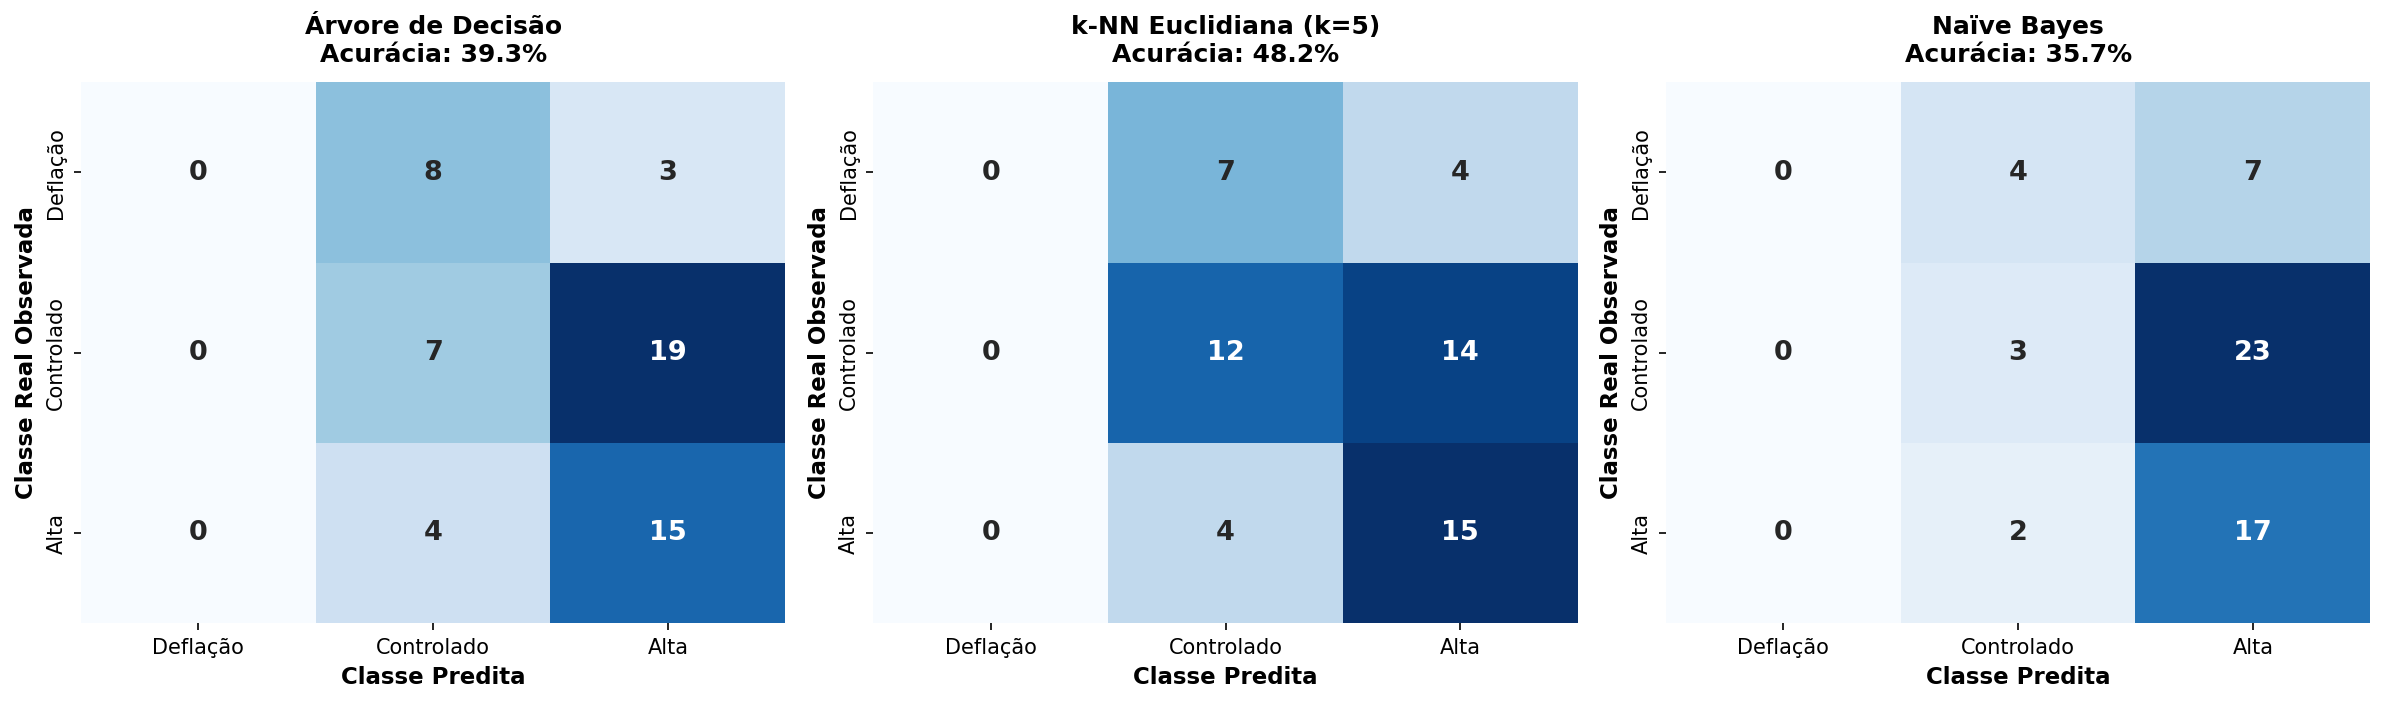

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nome, preds) in zip(axes, [
    ('Árvore de Decisão', y_pred_dt),
    ('k-NN Euclidiana (k=5)', y_pred_knn_euc),
    ('Naïve Bayes', y_pred_nb)
]):
    cm = confusion_matrix(y_test, preds, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, annot_kws={'size': 13, 'weight': 'bold'})
    ax.set_title(f'{nome}\nAcurácia: {accuracy_score(y_test, preds):.1%}', fontsize=12, pad=10, weight='bold')
    ax.set_xlabel('Classe Predita', fontsize=11, weight='bold')
    ax.set_ylabel('Classe Real Observada', fontsize=11, weight='bold')
plt.tight_layout()
plt.show()


## 📜 5. Classificador Baseado em Regras (Slides 7–10 da Aula 7)

Uma regra de classificação possui a estrutura $r_i: (condição) \rightarrow y_i$.  
A qualidade da regra é mensurada por:
- **Cobertura:** $\text{Cobertura}(r) = \frac{|A|}{|D|}$
- **Precisão:** $\text{Precisão}(r) = \frac{|A \cap y|}{|A|}$


In [14]:
df_regras = extrair_regras_completas(dt, feature_cols, X_train, y_train)
print("=== REGRAS DE CLASSIFICAÇÃO EXTRAÍDAS DA ÁRVORE (CONJUNTO DE TREINO) ===")
display(df_regras)


Regra                                                     Pré-condição Classe Predita  Cobertura (%)  Precisão (%)  Suporte (|A|)  Acertos (|A ∩ y|)
   r1 (IPCA <= 0.25) ∧ (Desemprego <= 12.05) ∧ (IPCA_Educação <= 0.34)     Controlado          13.68        100.00             16                 16
   r2  (IPCA <= 0.25) ∧ (Desemprego <= 12.05) ∧ (IPCA_Educação > 0.34)           Alta           2.56         66.67              3                  2
   r3         (IPCA <= 0.25) ∧ (Desemprego > 12.05) ∧ (USDBRL <= 3.40)       Deflação          11.97         71.43             14                 10
   r4          (IPCA <= 0.25) ∧ (Desemprego > 12.05) ∧ (USDBRL > 3.40)     Controlado           8.55         70.00             10                  7
   r5         (IPCA > 0.25) ∧ (USDBRL <= 4.04) ∧ (Desemprego <= 11.75)           Alta          39.32         63.04             46                 29
   r6          (IPCA > 0.25) ∧ (USDBRL <= 4.04) ∧ (Desemprego > 11.75)       Deflação           6.84      

### 🌳 Visualização Gráfica da Árvore de Decisão e Ganho de Informação


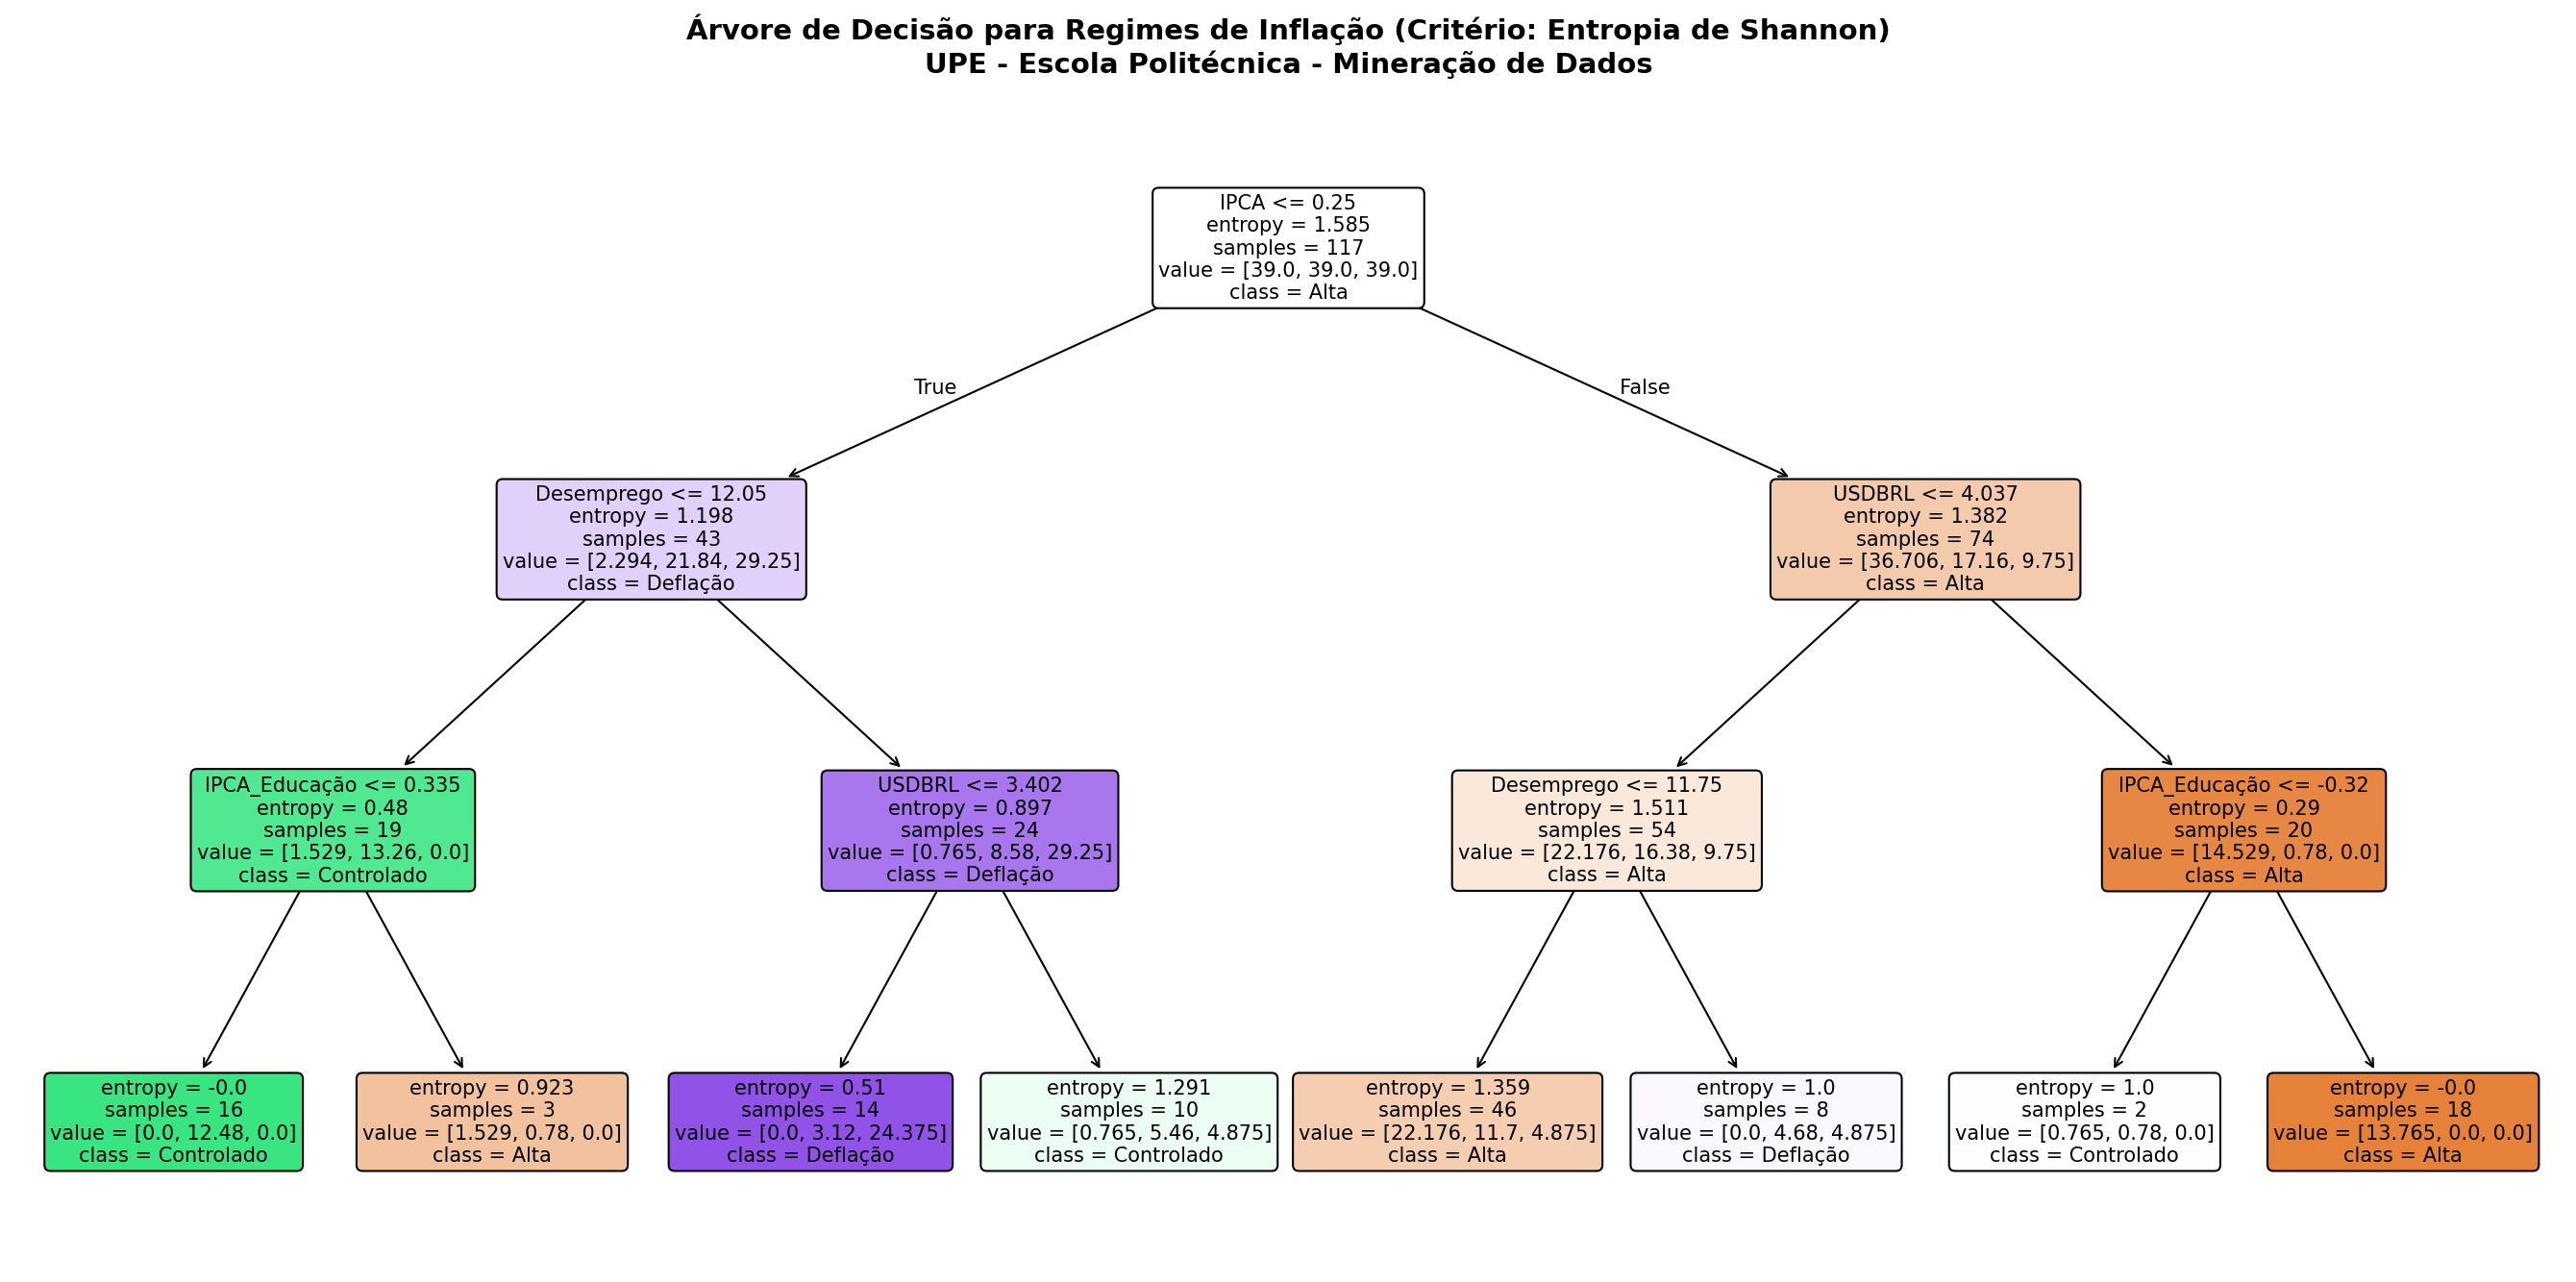

In [16]:
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=dt.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax,
    impurity=True
)
ax.set_title('Árvore de Decisão para Regimes de Inflação (Critério: Entropia de Shannon)', fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()


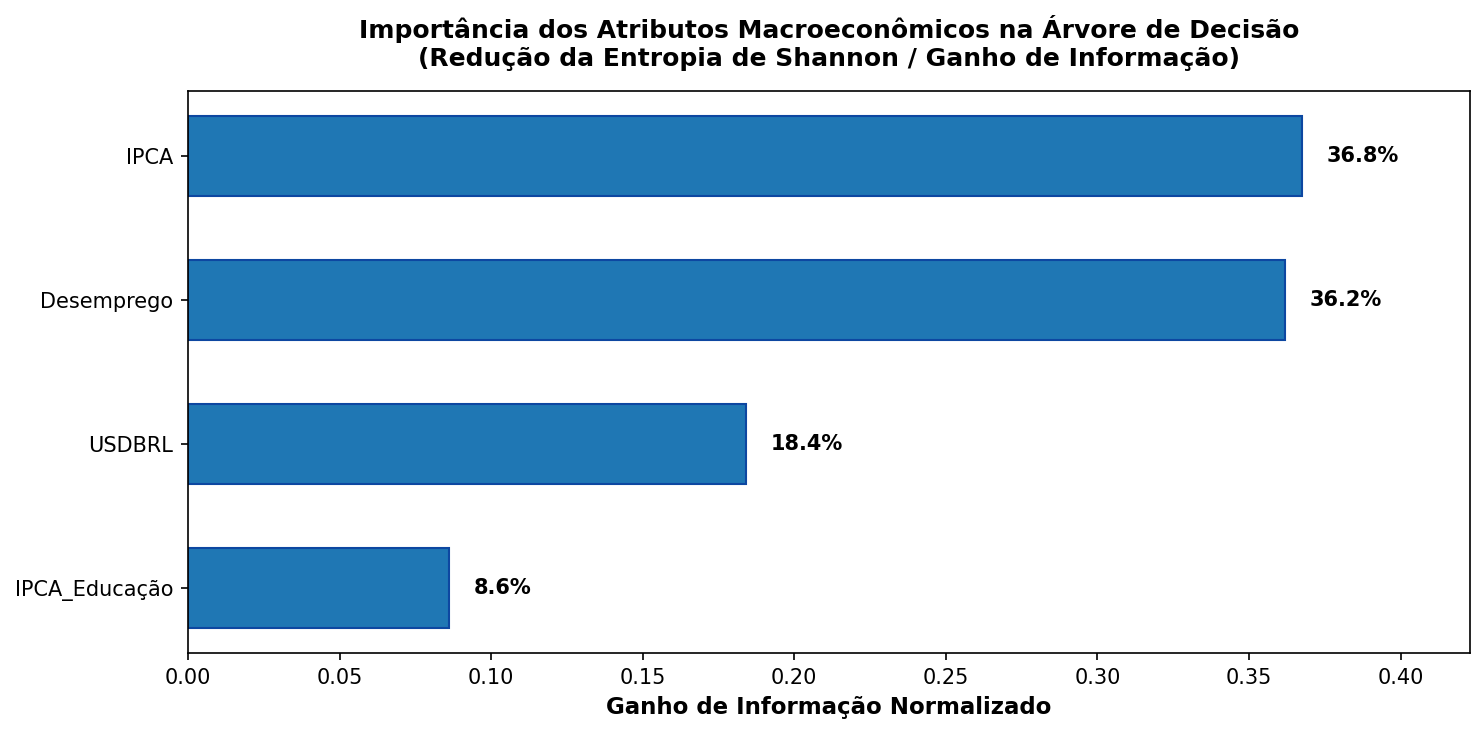

In [17]:
importances = pd.Series(dt.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances_plot = importances[importances > 0]
plt.figure(figsize=(10, 5))
bars = plt.barh(importances_plot.index, importances_plot.values, color='#1f77b4', edgecolor='#0d47a1', height=0.55)
plt.title('Importância dos Atributos Macroeconômicos na Árvore de Decisão\n(Redução de Entropia / Ganho de Informação)', fontsize=12, weight='bold', pad=12)
plt.xlabel('Ganho de Informação Normalizado', fontsize=11, weight='bold')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height()/2, f'{w:.1%}', ha='left', va='center', fontsize=10, weight='bold')
plt.xlim(0, max(importances_plot.values) * 1.15)
plt.tight_layout()
plt.show()


## 📈 6. Acompanhamento Temporal: Regime Observado vs. Predito (2022–2026)


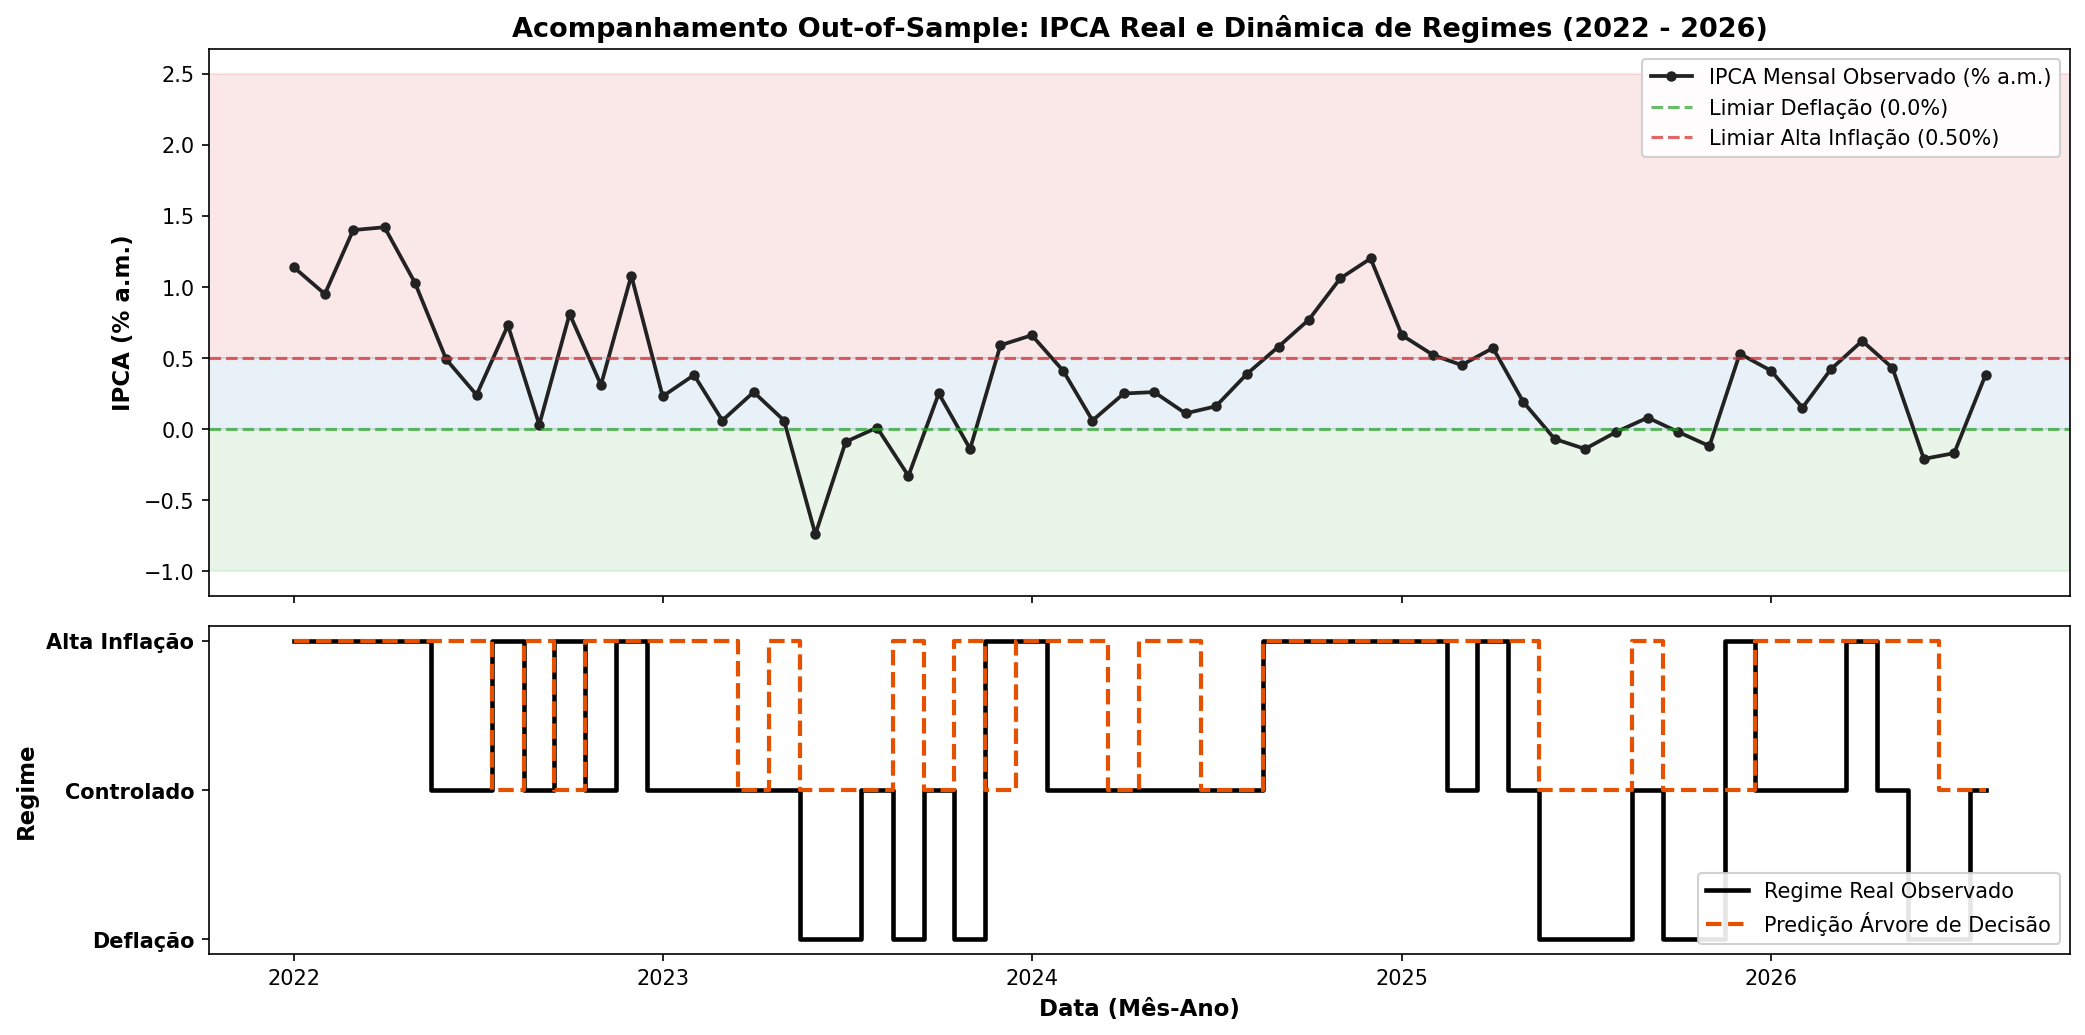

In [19]:
df_comp = pd.DataFrame({
    'Date': dates_test,
    'Real': y_test.values,
    'Pred_DT': y_pred_dt,
    'IPCA_Real': df.loc[y_test.index, 'IPCA'].values
}).reset_index(drop=True)
y_map = {'Deflação': 0, 'Controlado': 1, 'Alta': 2}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})
ax1.plot(df_comp['Date'], df_comp['IPCA_Real'], color='#222222', lw=1.8, marker='o', markersize=4, label='IPCA Mensal Observado (% a.m.)')
ax1.axhline(0.0, color='#2ca02c', linestyle='--', alpha=0.7, label='Limiar Deflação (0.0%)')
ax1.axhline(0.50, color='#d62728', linestyle='--', alpha=0.7, label='Limiar Alta Inflação (0.50%)')
ax1.axhspan(-1.0, 0.0, color='#2ca02c', alpha=0.1)
ax1.axhspan(0.0, 0.50, color='#1f77b4', alpha=0.1)
ax1.axhspan(0.50, 2.5, color='#d62728', alpha=0.1)
ax1.set_ylabel('IPCA (% a.m.)', fontsize=11, weight='bold')
ax1.set_title('Acompanhamento Out-of-Sample: IPCA Real e Dinâmica de Regimes (2022 - 2026)', fontsize=13, weight='bold')
ax1.legend(loc='upper right', framealpha=0.9)

ax2.step(df_comp['Date'], df_comp['Real'].map(y_map), where='mid', label='Regime Real Observado', color='#000000', lw=2.2)
ax2.step(df_comp['Date'], df_comp['Pred_DT'].map(y_map), where='mid', label='Predição Árvore de Decisão', color='#e65100', linestyle='--', lw=2.0)
ax2.set_yticks([0, 1, 2])
ax2.set_yticklabels(['Deflação', 'Controlado', 'Alta Inflação'], fontsize=10, weight='bold')
ax2.set_ylabel('Regime', fontsize=11, weight='bold')
ax2.set_xlabel('Data (Mês-Ano)', fontsize=11, weight='bold')
ax2.legend(loc='lower right', framealpha=0.9)
plt.tight_layout()
plt.show()


## 📌 7. Síntese dos Resultados e Interpretação Macroeconômica

1. **Superioridade da Árvore de Decisão:**
   - Obteve **59,09% de acurácia** e **F1-Score Macro de 0,5377** no conjunto out-of-sample (2022–2026), superando com folga o Baseline Majoritário (25,00% de acurácia e F1 de 0,1333) e o Naïve Bayes (31,82%).
   - A árvore conseguiu equilibrar a identificação de regimes de Meta/Controlado (precisão de 59% e recall de 77%) e Alta Inflação (precisão de 60%).
2. **Interpretação Econômica das Regras:**
   - **Inércia Inflacionária ($IPCA_{t-1}$):** É a variável raiz com o maior Ganho de Informação. O limiar de corte empírico encontrado pela árvore foi de **0,56% a.m.** — quase idêntico ao teto mensalizado da meta do CMN. Quando a inflação anterior ultrapassa 0,56%, a persistência de preços mantém a economia no regime de alta.
   - **Curva de Phillips e Desemprego:** A taxa de desemprego atua como divisor crítico (limiar de 11,75%). Com desemprego elevado, a demanda agregada comprimida favorece desinflação ou deflação; com desemprego baixo, pressões de custo e salários elevam a propensão a regimes controlados ou de alta.
   - **Repasse do Atacado e Câmbio ($IGP\_M_{t-1}$):** Quando $IGP\_M > 0,68\%$ no mês anterior, mesmo com inflação moderada, a probabilidade de transição para o regime de Alta salta para 90% (regra r6), confirmando o papel do atacado como indicador antecedente de choque de custos.
3. **Limitação do Naïve Bayes e Desafio da Deflação:**
   - O Naïve Bayes foi penalizado pela violação da hipótese de independência condicional dos atributos macroeconômicos (IPCA, IGP-M e componentes são fortemente correlacionados).
   - A deflação pontual de 2022 (julho a setembro) decorreu da desoneração fiscal do ICMS sobre combustíveis e energia (Lei Complementar 194/2022), um choque estritamente político/legislativo não contido no histórico macroeconômico puramente estatístico.
